# 02 — Bronze: perfilado

Análisis previo de los CSV antes de la capa Silver. Se lee **con Spark, sin inferir tipos**, y no se transforma nada.

| Sección | Contenido |
| --- | --- |
| 1 | Formato real de cada archivo (SIAF → SISMEPRE → RENAMU) |
| 2 | F1 SIAF: columnas, métricas por año, perfil de columnas, ejecutoras, unicidad |
| 3 | F2 SISMEPRE: revisión general de columnas → llaves → relaciones → calidad → clasificación A–G |
| 4 | F3 RENAMU: inventario y gráficos por edición → ediciones 2020–2026 |
| 5 | Conexión de prueba entre las tres fuentes |
| 6 | Bitácora de la ejecución |

## 0. Configuración

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ARQUITECTURA.md").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import json, re, uuid, logging
from collections import Counter
from datetime import datetime, timezone
from itertools import combinations

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from src.config import cargar_config, ruta
from src.spark import crear_sesion
from src import bronze
from src.perfilado import detectar_formato, leer_csv, a_pandas, perfil_columnas

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200)
cfg = cargar_config()
RUN_ID = f"bronze_perfilado_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}_{uuid.uuid4().hex[:6]}"
spark = crear_sesion("bronze_perfilado")

# Inventario desde el manifest (última carpeta de descarga de cada fuente)
man = pd.DataFrame(bronze.leer_manifest()["archivos"])
man["ext"] = man["archivo"].str.rsplit(".", n=1).str[-1].str.lower()
ultima = man.groupby("fuente")["fecha_carpeta"].max()
man = man[man.apply(lambda r: r["fecha_carpeta"] == ultima[r["fuente"]], axis=1)]
csvs = man[man["ext"] == "csv"].copy()
csvs["abs"] = csvs["ruta"].map(lambda r: str(RAIZ / r))

CHECKS = []   # verificaciones del perfilado -> bitácora
def check(id_, descripcion, evaluadas, fallidas, severidad="alta"):
    estado = "OK" if fallidas == 0 else ("FALLA" if severidad == "critica" else "ALERTA")
    CHECKS.append({"regla": id_, "descripcion": descripcion, "severidad": severidad,
                   "filas_evaluadas": int(evaluadas), "filas_fallidas": int(fallidas), "estado": estado})
    return estado

print("Ejecución:", RUN_ID)
print(csvs.groupby("fuente").agg(csv=("ruta", "count"), GB=("bytes", lambda s: round(s.sum() / 1e9, 3))).to_string())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/20 22:01:14 WARN Utils: Your hostname, Rodrigo, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/20 22:01:14 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 22:01:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Ejecución: bronze_perfilado_20261121T030112Z_1f3e21
         csv     GB
fuente             
F1        18  7.335
F2         7  0.059
F3      1028  0.272


## 1. Formato real de cada archivo (encoding y delimitador)

In [2]:
fmt_rows = []
for r in csvs.itertuples():
    f = detectar_formato(Path(r.abs))
    fmt_rows.append({"fuente": r.fuente, "anio": r.anio, "ruta": r.ruta, "abs": r.abs, "archivo": r.archivo,
                     "filas_fisicas": r.filas, **{k: v for k, v in f.items() if k != "columnas"}, "lista_columnas": f["columnas"]})
df_fmt = pd.DataFrame(fmt_rows)
VER = ["archivo", "encoding", "bom", "delimitador", "salto_linea", "n_columnas", "filas_fisicas"]

### 1.1 F1 SIAF

In [3]:
display(df_fmt[df_fmt["fuente"] == "F1"].sort_values("anio")[["anio"] + VER])

,anio,archivo,encoding,bom,delimitador,salto_linea,n_columnas,filas_fisicas
1028,2009.0,2009-Ingreso.csv,UTF-8,False,",",CRLF,36,1235428.0
1029,2010.0,2010-Ingreso.csv,UTF-8,False,",",CRLF,36,1320104.0
1030,2011.0,2011-Ingreso.csv,UTF-8,False,",",CRLF,36,1348362.0
1031,2012.0,2012-Ingreso.csv,UTF-8,False,",",CRLF,36,759578.0
1032,2013.0,2013-Ingreso.csv,UTF-8,False,",",CRLF,36,721663.0
1033,2014.0,2014-Ingreso.csv,UTF-8,False,",",CRLF,36,753998.0
1034,2015.0,2015-Ingreso.csv,UTF-8,False,",",CRLF,36,781007.0
1035,2016.0,2016-Ingreso.csv,UTF-8,False,",",CRLF,36,764731.0
1036,2017.0,2017-Ingreso.csv,UTF-8,False,",",CRLF,36,683816.0
1037,2018.0,2018-Ingreso.csv,UTF-8,False,",",CRLF,36,656859.0


### 1.2 F2 SISMEPRE

In [4]:
display(df_fmt[df_fmt["fuente"] == "F2"].sort_values("archivo")[VER])

,archivo,encoding,bom,delimitador,salto_linea,n_columnas,filas_fisicas
1046,rentas_ano_aplicacion.csv,UTF-8,False,",",CRLF,9,27.0
1047,rentas_entidad_estado.csv,UTF-8,False,",",CRLF,13,20391.0
1048,rentas_esat_estadistica_atm.csv,UTF-8,False,",",CRLF,42,149492.0
1049,rentas_estadistica.csv,UTF-8,False,",",CRLF,7,260.0
1050,rentas_formulario.csv,UTF-8,False,",",CRLF,10,108.0
1051,rentas_preguntas.csv,UTF-8,False,",",CRLF,15,836.0
1052,rentas_respuestas.csv,UTF-8,False,",",CRLF,11,322675.0


### 1.3 F3 RENAMU (resumen por edición; más de 1 000 archivos)

In [5]:
f3 = df_fmt[df_fmt["fuente"] == "F3"].copy()
f3["anio"] = f3["anio"].astype(int)
f3["formulario"] = f3["ruta"].map(lambda r: "F02 centros poblados" if "_F02_" in r else "F01 municipalidades")
display(f3.groupby(["anio", "formulario"]).agg(
    csv=("ruta", "count"), encoding=("encoding", lambda s: "/".join(sorted(set(s)))), bom=("bom", "any"),
    delimitador=("delimitador", lambda s: "/".join(sorted(set(s)))), salto_linea=("salto_linea", lambda s: "/".join(sorted(set(s))))))

,,csv,encoding,bom,delimitador,salto_linea
anio,formulario,,,,,
2009,F01 municipalidades,98,ISO-8859-1,False,;,CRLF
2010,F01 municipalidades,98,ISO-8859-1,False,;,CRLF
2011,F01 municipalidades,98,ISO-8859-1,False,;,CRLF
2012,F01 municipalidades,108,ISO-8859-1,False,;,CRLF
2013,F01 municipalidades,107,ISO-8859-1,False,;,CRLF
2014,F01 municipalidades,96,ISO-8859-1,False,;,CRLF
2015,F01 municipalidades,115,ISO-8859-1,False,;,CRLF
2016,F01 municipalidades,111,ISO-8859-1,False,;,CRLF
2017,F01 municipalidades,116,ISO-8859-1,False,;,CRLF


## 2. F1 SIAF — Presupuesto y ejecución de ingreso

### 2.1 Columnas esperadas vs. reales

In [6]:
siaf = df_fmt[df_fmt["fuente"] == "F1"].sort_values("anio")
ESPERADAS_SIAF = siaf[siaf["anio"] == 2024]["lista_columnas"].iloc[0]   # referencia: el archivo anual más reciente
cols_siaf = pd.DataFrame([{
    "anio": int(r.anio), "n_columnas": r.n_columnas, "iguales_y_en_orden": r.lista_columnas == ESPERADAS_SIAF,
    "faltan": ", ".join(sorted(set(ESPERADAS_SIAF) - set(r.lista_columnas))) or "—",
    "sobran": ", ".join(sorted(set(r.lista_columnas) - set(ESPERADAS_SIAF))) or "—",
} for r in siaf.itertuples()])
display(cols_siaf)
print("Columnas:", ESPERADAS_SIAF)
check("BRZ-F1-001", "Los 18 archivos del SIAF tienen las mismas 36 columnas en el mismo orden", len(cols_siaf), (~cols_siaf["iguales_y_en_orden"]).sum(), "critica")

FMT_SIAF = detectar_formato(RAIZ / siaf.iloc[-1]["ruta"])
df_siaf = (leer_csv(spark, siaf["abs"].tolist(), FMT_SIAF)
           .withColumn("anio_archivo", F.regexp_extract(F.input_file_name(), r"(\d{4})-Ingreso", 1).cast("int")))

,anio,n_columnas,iguales_y_en_orden,faltan,sobran
0,2009,36,True,—,—
1,2010,36,True,—,—
2,2011,36,True,—,—
3,2012,36,True,—,—
4,2013,36,True,—,—
5,2014,36,True,—,—
6,2015,36,True,—,—
7,2016,36,True,—,—
8,2017,36,True,—,—
9,2018,36,True,—,—


Columnas: ['ANO_DOC', 'MES_DOC', 'NIVEL_GOBIERNO', 'NIVEL_GOBIERNO_NOMBRE', 'SECTOR', 'SECTOR_NOMBRE', 'PLIEGO', 'PLIEGO_NOMBRE', 'SEC_EJEC', 'EJECUTORA', 'EJECUTORA_NOMBRE', 'DEPARTAMENTO_EJECUTORA', 'DEPARTAMENTO_EJECUTORA_NOMBRE', 'PROVINCIA_EJECUTORA', 'PROVINCIA_EJECUTORA_NOMBRE', 'DISTRITO_EJECUTORA', 'DISTRITO_EJECUTORA_NOMBRE', 'FUENTE_FINANCIAMIENTO', 'FUENTE_FINANCIAMIENTO_NOMBRE', 'RUBRO', 'RUBRO_NOMBRE', 'TIPO_RECURSO', 'TIPO_RECURSO_NOMBRE', 'GENERICA', 'GENERICA_NOMBRE', 'SUBGENERICA', 'SUBGENERICA_NOMBRE', 'SUBGENERICA_DET', 'SUBGENERICA_DET_NOMBRE', 'ESPECIFICA', 'ESPECIFICA_NOMBRE', 'ESPECIFICA_DET', 'ESPECIFICA_DET_NOMBRE', 'MONTO_PIA', 'MONTO_PIM', 'MONTO_RECAUDADO']


### 2.2 Pasada 1 — métricas por año

In [7]:
num = lambda c: F.col(c).cast("double")
es_m = F.col("NIVEL_GOBIERNO") == "M"
anual = (df_siaf.groupBy("anio_archivo").agg(
    F.count("*").alias("filas_spark"),
    F.sum(es_m.cast("long")).alias("filas_M"),
    F.sum((F.col("NIVEL_GOBIERNO") == "R").cast("long")).alias("filas_R"),
    F.sum((F.col("NIVEL_GOBIERNO") == "E").cast("long")).alias("filas_E"),
    F.sum((~F.col("NIVEL_GOBIERNO").isin("E", "M", "R")).cast("long")).alias("filas_otro_nivel"),
    F.sum((F.col("ANO_DOC").cast("int") != F.col("anio_archivo")).cast("long")).alias("ano_doc_distinto"),
    F.min(F.col("MES_DOC").cast("int")).alias("mes_min"), F.max(F.col("MES_DOC").cast("int")).alias("mes_max"),
    F.sum(((num("MONTO_PIA") == 0) & (num("MONTO_PIM") == 0) & (num("MONTO_RECAUDADO") == 0)).cast("long")).alias("filas_montos_cero"),
    F.sum((num("MONTO_RECAUDADO") < 0).cast("long")).alias("recaudado_negativo"),
    F.sum((num("MONTO_PIM") < 0).cast("long")).alias("pim_negativo"),
    F.sum(F.when(es_m, num("MONTO_PIA"))).alias("pia_M"),
    F.sum(F.when(es_m & (F.col("MES_DOC") == "1"), num("MONTO_PIA"))).alias("pia_M_enero"),
    F.sum(F.when(es_m, num("MONTO_PIM"))).alias("pim_M"),
    F.sum(F.when(es_m, num("MONTO_RECAUDADO"))).alias("recaudado_M"),
    F.countDistinct(F.when(es_m, F.concat_ws("-", "SEC_EJEC", "MES_DOC"))).alias("ejecutora_mes_M"),
)).orderBy("anio_archivo")
df_anual = a_pandas(anual)
df_anual = df_anual.merge(siaf[["anio", "filas_fisicas"]].rename(columns={"anio": "anio_archivo"}).astype({"anio_archivo": int}), on="anio_archivo")
df_anual["dif_spark_vs_fisico"] = df_anual["filas_spark"] - df_anual["filas_fisicas"].astype(int)
df_anual["filas_M_por_ejecutora_mes"] = (df_anual["filas_M"] / df_anual["ejecutora_mes_M"]).round(1)
df_anual["pct_pia_en_enero"] = (100 * df_anual["pia_M_enero"] / df_anual["pia_M"]).round(1)
df_anual["pct_filas_montos_cero"] = (100 * df_anual["filas_montos_cero"] / df_anual["filas_spark"]).round(1)
for c in ("pia_M", "pim_M", "recaudado_M"):
    df_anual[c + "_millones"] = (df_anual[c] / 1e6).round(1)
df_anual = df_anual.drop(columns=["pia_M", "pim_M", "recaudado_M", "pia_M_enero", "ejecutora_mes_M"]).set_index("anio_archivo")
display(df_anual)

check("BRZ-F1-002", "Conteo de Spark = conteo físico del manifest (sin saltos de línea dentro de campos)", len(df_anual), (df_anual["dif_spark_vs_fisico"] != 0).sum(), "critica")
check("BRZ-F1-003", "NIVEL_GOBIERNO solo toma E, R o M", int(df_anual["filas_spark"].sum()), int(df_anual["filas_otro_nivel"].sum()))
check("BRZ-F1-004", "ANO_DOC coincide con el año del archivo", int(df_anual["filas_spark"].sum()), int(df_anual["ano_doc_distinto"].sum()), "critica")

,filas_spark,filas_M,filas_R,filas_E,filas_otro_nivel,ano_doc_distinto,mes_min,mes_max,filas_montos_cero,recaudado_negativo,pim_negativo,filas_fisicas,dif_spark_vs_fisico,filas_M_por_ejecutora_mes,pct_pia_en_enero,pct_filas_montos_cero,pia_M_millones,pim_M_millones,recaudado_M_millones
anio_archivo,,,,,,,,,,,,,,,,,,,
2009,1235428,1080470,90407,64551,0,0,1,12,349137,3309,90,1235428.0,0,49.1,7.7,28.3,11999.8,20695.9,18496.6
2010,1320104,1159789,94370,65945,0,0,1,12,415152,4539,77,1320104.0,0,52.7,7.9,31.4,9138.8,20936.5,20161.7
2011,1348362,1185119,97197,66046,0,0,1,12,424588,4444,12,1348362.0,0,53.8,7.7,31.5,10793.5,21314.0,20858.4
2012,759578,638925,70586,50067,0,0,1,12,149809,4894,17,759578.0,0,28.9,100.0,19.7,14826.2,27217.4,26288.4
2013,721663,590342,76959,54362,0,0,1,12,146111,4722,36,721663.0,0,26.8,100.0,20.2,17559.5,28965.6,26579.9
2014,753998,611673,83258,59067,0,0,1,12,150219,5384,258,753998.0,0,27.6,100.0,19.9,16353.0,27088.6,25872.6
2015,781007,632600,86962,61445,0,0,1,12,149074,5295,3668,781007.0,0,28.3,100.0,19.1,15230.7,24004.5,23399.8
2016,764731,613544,89084,62103,0,0,1,12,148618,6241,183,764731.0,0,27.2,100.0,19.4,14269.9,26468.3,25979.1
2017,683816,550949,77922,54945,0,0,1,12,44609,7862,673,683816.0,0,24.4,100.0,6.5,14553.4,29127.8,28884.8


'OK'

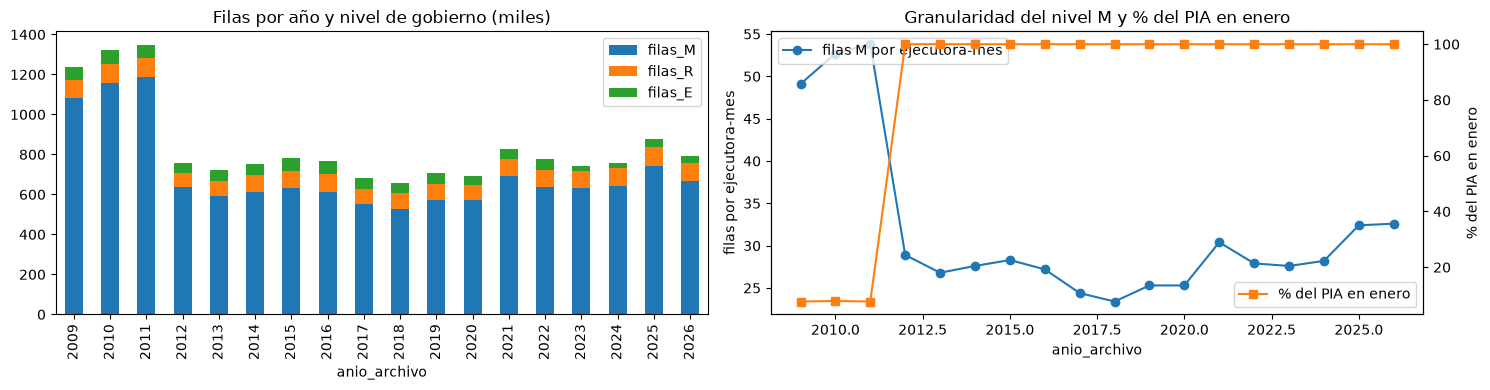

In [8]:
# Visualización: filas por año y nivel, granularidad del nivel M y % del PIA registrado en enero
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
df_anual[["filas_M", "filas_R", "filas_E"]].div(1e3).plot.bar(stacked=True, ax=ax[0], title="Filas por año y nivel de gobierno (miles)")
df_anual["filas_M_por_ejecutora_mes"].plot(ax=ax[1], marker="o", label="filas M por ejecutora-mes", title="Granularidad del nivel M y % del PIA en enero")
ax[1].set_ylabel("filas por ejecutora-mes"); ax[1].legend(loc="upper left")
ax_r = ax[1].twinx(); df_anual["pct_pia_en_enero"].plot(ax=ax_r, marker="s", color="tab:orange", label="% del PIA en enero")
ax_r.set_ylabel("% del PIA en enero"); ax_r.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 2.3 Pasada 2 — perfil de columnas (nulos, vacíos y rangos)

In [9]:
MONTOS = ["MONTO_PIA", "MONTO_PIM", "MONTO_RECAUDADO"]
perf_siaf = perfil_columnas(df_siaf.drop("anio_archivo"), "F1", "siaf", numericas=MONTOS + ["ANO_DOC", "MES_DOC"])
display(perf_siaf.drop(columns=["fuente", "tabla"]).set_index("columna"))
check("BRZ-F1-005", "Montos numéricos parseables (PIA, PIM, recaudado)", int(perf_siaf["filas"].iloc[0]) * 3,
      int(perf_siaf[perf_siaf["columna"].isin(MONTOS)]["no_numericos"].sum()), "critica")

# ¿En qué nivel de gobierno están los vacíos de SECTOR y PLIEGO?
display(a_pandas(df_siaf.groupBy("NIVEL_GOBIERNO").agg(F.count("*").alias("filas"),
        F.sum((F.trim("SECTOR") == "").cast("long")).alias("sector_vacio"), F.sum((F.trim("PLIEGO") == "").cast("long")).alias("pliego_vacio"))))

26/11/20 22:01:36 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/11/20 22:01:36 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/11/20 22:02:42 WARN DAGScheduler: Broadcasting large task binary with size 6.7 MiB


,filas,nulos,vacios,pct_nulo_o_vacio,distintos_aprox,largo_min,largo_max,no_numericos,min,max
columna,,,,,,,,,,
ANO_DOC,15202372,0,0,0.00,18,4,4,0.0,2.009000e+03,2.026000e+03
MES_DOC,15202372,0,0,0.00,12,1,2,0.0,1.000000e+00,1.200000e+01
NIVEL_GOBIERNO,15202372,0,0,0.00,3,1,1,NaN,NaN,NaN
NIVEL_GOBIERNO_NOMBRE,15202372,0,0,0.00,3,17,20,NaN,NaN,NaN
SECTOR,15202372,0,12749727,83.87,33,1,2,NaN,NaN,NaN
SECTOR_NOMBRE,15202372,0,12749727,83.87,36,1,50,NaN,NaN,NaN
PLIEGO,15202372,0,12749727,83.87,189,1,3,NaN,NaN,NaN
PLIEGO_NOMBRE,15202372,0,12749727,83.87,281,1,107,NaN,NaN,NaN
SEC_EJEC,15202372,0,0,0.00,2998,1,6,NaN,NaN,NaN


,NIVEL_GOBIERNO,filas,sector_vacio,pliego_vacio
0,M,12749727,12749727,12749727
1,R,1525176,0,0
2,E,927469,0,0


### 2.4 Pasada 3 — ejecutoras del nivel M y consistencia de `SEC_EJEC`

In [10]:
ubigeo = F.concat(F.lpad("DEPARTAMENTO_EJECUTORA", 2, "0"), F.lpad("PROVINCIA_EJECUTORA", 2, "0"), F.lpad("DISTRITO_EJECUTORA", 2, "0"))
tipo_ejec = (F.when(F.col("EJECUTORA_NOMBRE").startswith("MUNICIPALIDAD DISTRITAL"), "Municipalidad distrital")
              .when(F.col("EJECUTORA_NOMBRE").startswith("MUNICIPALIDAD PROVINCIAL"), "Municipalidad provincial")
              .when(F.col("EJECUTORA_NOMBRE").startswith("MUNICIPALIDAD METROPOLITANA"), "Municipalidad metropolitana")
              .when(F.col("EJECUTORA_NOMBRE").startswith("MANCOMUNIDAD"), "Mancomunidad municipal")
              .otherwise("Otra"))
df_ejec = a_pandas(df_siaf.where(es_m).select(F.col("anio_archivo").alias("anio"), "SEC_EJEC", "EJECUTORA_NOMBRE",
                   ubigeo.alias("ubigeo"), tipo_ejec.alias("tipo_ejecutora"), F.length("DEPARTAMENTO_EJECUTORA").alias("largo_dep")).distinct())
display(df_ejec.drop_duplicates(["anio", "SEC_EJEC"]).pivot_table(index="anio", columns="tipo_ejecutora", values="SEC_EJEC", aggfunc="count", fill_value=0))

consist = df_ejec.groupby(["anio", "SEC_EJEC"]).agg(n_ubigeo=("ubigeo", "nunique"), n_nombre=("EJECUTORA_NOMBRE", "nunique"))
muni = df_ejec[df_ejec["tipo_ejecutora"].str.startswith("Municipalidad")]
tabla_consist = pd.DataFrame({
    "sec_ejec_con_varios_ubigeos": consist.groupby("anio")["n_ubigeo"].apply(lambda s: (s > 1).sum()),
    "sec_ejec_con_varios_nombres": consist.groupby("anio")["n_nombre"].apply(lambda s: (s > 1).sum()),
    "ubigeos_con_varias_municipalidades": muni.groupby(["anio", "ubigeo"])["SEC_EJEC"].nunique().gt(1).groupby("anio").sum(),
    "ejecutoras_con_codigo_de_1_digito": df_ejec[df_ejec["largo_dep"] == 1].groupby("anio")["SEC_EJEC"].nunique(),
}).fillna(0).astype(int)
display(tabla_consist)
check("BRZ-F1-006", "Un UBIGEO corresponde a una sola municipalidad por año", int(muni.groupby("anio")["ubigeo"].nunique().sum()),
      int(tabla_consist["ubigeos_con_varias_municipalidades"].sum()), "critica")

tipo_ejecutora,Mancomunidad municipal,Municipalidad distrital,Municipalidad metropolitana,Municipalidad provincial
anio,,,,
2009,0,1639,1,194
2010,0,1639,0,195
2011,0,1642,0,195
2012,19,1643,0,195
2013,25,1644,1,194
2014,30,1651,1,195
2015,32,1658,1,195
2016,40,1677,1,195
2017,43,1678,1,195


,sec_ejec_con_varios_ubigeos,sec_ejec_con_varios_nombres,ubigeos_con_varias_municipalidades,ejecutoras_con_codigo_de_1_digito
anio,,,,
2009,0,0,0,0
2010,0,0,0,0
2011,0,0,0,0
2012,0,0,0,4
2013,0,1,0,0
2014,0,3,0,0
2015,0,0,0,0
2016,0,1,0,0
2017,0,1,0,0


'OK'

### 2.5 Pasada 4 — duplicados y unicidad de la llave de negocio

In [11]:
LLAVE_SIAF = ["ANO_DOC", "MES_DOC", "SEC_EJEC", "FUENTE_FINANCIAMIENTO", "RUBRO", "TIPO_RECURSO",
              "GENERICA", "SUBGENERICA", "SUBGENERICA_DET", "ESPECIFICA", "ESPECIFICA_DET"]
todas = [c for c in df_siaf.columns if c != "anio_archivo"]
dups = a_pandas(df_siaf.groupBy("anio_archivo").agg(
    F.count("*").alias("filas"),
    (F.count("*") - F.countDistinct(F.sha2(F.concat_ws("|", *[F.coalesce(F.col(c), F.lit("∅")) for c in todas]), 256))).alias("duplicados_exactos"),
    (F.count("*") - F.countDistinct(F.concat_ws("|", *LLAVE_SIAF))).alias("duplicados_llave"),
).orderBy("anio_archivo")).set_index("anio_archivo")
display(dups.T)
check("BRZ-F1-007", "Sin filas duplicadas exactas", int(dups["filas"].sum()), int(dups["duplicados_exactos"].sum()), "critica")
check("BRZ-F1-008", "Llave de negocio única (año, mes, ejecutora, fuente, rubro, tipo de recurso, clasificador)", int(dups["filas"].sum()), int(dups["duplicados_llave"].sum()))

anio_archivo,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
filas,1235428,1320104,1348362,759578,721663,753998,781007,764731,683816,656859,706695,692729,828317,774954,743452,758116,878733,793830
duplicados_exactos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
duplicados_llave,0,21,64,70,3,27,20,16,20,7,5,9,3,4,4,0,16,2


'ALERTA'

## 3. F2 SISMEPRE — Meta del impuesto predial

No hay diccionarios (P-003). Por eso las llaves y relaciones **se deducen de los datos**: primero se miran las columnas de los 7 archivos, luego se busca la llave de cada uno y al final se prueban las relaciones.

### 3.1 Revisión general: ¿qué columnas comparten los archivos?

In [12]:
f2 = df_fmt[df_fmt["fuente"] == "F2"].sort_values("archivo")
SENSIBLES_F2 = {"CORREO", "USUARIO_ENVIO_ID"}          # datos personales: solo se cuentan
dfs_f2, estructura_f2 = {}, []
for r in f2.itertuples():
    d = leer_csv(spark, r.abs, detectar_formato(RAIZ / r.ruta), corrupto=True).cache()
    n, corr = d.count(), d.where(F.col("_corrupt_record").isNotNull()).count()
    dfs_f2[r.archivo] = d.where(F.col("_corrupt_record").isNull()).drop("_corrupt_record").cache()
    estructura_f2.append({"archivo": r.archivo, "filas_fisicas": int(r.filas_fisicas), "filas_spark": n, "filas_mal_formadas": corr,
                          "columnas": len(dfs_f2[r.archivo].columns), "columnas_sensibles": ", ".join(sorted(SENSIBLES_F2 & set(d.columns))) or "—"})

presencia = pd.DataFrame({a.replace("rentas_", "").replace(".csv", ""): {c: "●" for c in d.columns} for a, d in dfs_f2.items()}).fillna("")
presencia["en_n_archivos"] = (presencia != "").sum(axis=1)
compartidas = presencia[presencia["en_n_archivos"] > 1].sort_values("en_n_archivos", ascending=False)
print(f"Columnas totales: {len(presencia)} · compartidas por 2 o más archivos: {len(compartidas)}")
display(compartidas)

Columnas totales: 80 · compartidas por 2 o más archivos: 11


,ano_aplicacion,entidad_estado,esat_estadistica_atm,estadistica,formulario,preguntas,respuestas,en_n_archivos
ANO_APLICACION,●,●,●,●,●,●,●,7
PERIODO,●,●,●,●,●,●,●,7
FORMULARIO_ID,,,●,●,●,●,●,5
ESTADO_REGISTRO,,,,●,●,●,●,4
SEC_EJEC,,●,●,,,,●,3
ESTADO,●,●,,,,,,2
CLASIFICACION,,●,,,●,,,2
ANO_ESTADISTICA,,,●,●,,,,2
TIPO_META,,●,●,,,,,2
MES_ESTADISTICA,,,●,●,,,,2


In [13]:
# Cardinalidad de las columnas compartidas: los códigos tienen pocos valores distintos y largo fijo
card = []
for a, d in dfs_f2.items():
    for c in [c for c in compartidas.index if c in d.columns]:
        r = d.agg(F.countDistinct(c).alias("distintos"), F.min(F.length(c)).alias("lmin"), F.max(F.length(c)).alias("lmax")).first()
        card.append({"columna": c, "archivo": a.replace("rentas_", "").replace(".csv", ""), "valor": f"{r['distintos']} ({r['lmin']}–{r['lmax']} car.)"})
display(pd.DataFrame(card).pivot_table(index="columna", columns="archivo", values="valor", aggfunc="first").fillna("").loc[compartidas.index])

archivo,ano_aplicacion,entidad_estado,esat_estadistica_atm,estadistica,formulario,preguntas,respuestas
columna,,,,,,,
ANO_APLICACION,14 (4–4 car.),14 (4–4 car.),9 (4–4 car.),7 (4–4 car.),7 (4–4 car.),6 (4–4 car.),5 (4–4 car.)
PERIODO,4 (1–1 car.),4 (1–1 car.),4 (1–1 car.),2 (1–1 car.),2 (1–1 car.),2 (1–1 car.),2 (1–1 car.)
FORMULARIO_ID,,,12 (1–2 car.),11 (1–2 car.),16 (1–2 car.),6 (1–1 car.),6 (1–1 car.)
ESTADO_REGISTRO,,,,1 (1–1 car.),1 (1–1 car.),1 (1–1 car.),2 (1–1 car.)
SEC_EJEC,,1485 (6–6 car.),1128 (6–6 car.),,,,999 (6–6 car.)
ESTADO,2 (1–1 car.),1 (1–1 car.),,,,,
CLASIFICACION,,7 (1–1 car.),,,2 (9–13 car.),,
ANO_ESTADISTICA,,,16 (4–4 car.),13 (4–4 car.),,,
TIPO_META,,8 (1–2 car.),1 (1–1 car.),,,,


### 3.2 Búsqueda de llaves: la combinación mínima de columnas que identifica cada fila

In [14]:
# Candidatas: columnas compartidas, identificadores propios (*_ID), años y meses
def candidatas(cols):
    return [c for c in cols if c in compartidas.index or c.endswith("_ID") or c.startswith(("ANO_", "MES_")) or c == "UBIGEO"]

llaves = []
for a, d in dfs_f2.items():
    pdf = a_pandas(d.select(*candidatas(d.columns)))
    cand, encontrada = list(pdf.columns), None
    for k in range(1, len(cand) + 1):
        encontrada = next((combo for combo in combinations(cand, k) if not pdf.duplicated(subset=list(combo)).any()), None)
        if encontrada:
            break
    llaves.append({"archivo": a, "filas": len(pdf), "columnas_candidatas": ", ".join(cand), "llave_minima": " + ".join(encontrada) if encontrada else "(ninguna)"})
df_llaves = pd.DataFrame(llaves)
display(df_llaves)
check("BRZ-F2-002", "Cada archivo del SISMEPRE tiene una llave natural deducida de sus columnas", len(df_llaves), int((df_llaves["llave_minima"] == "(ninguna)").sum()))

,archivo,filas,columnas_candidatas,llave_minima
0,rentas_ano_aplicacion.csv,27,"ANO_APLICACION, ANO_APLICACION_INICIO, ANO_APL...",ANO_APLICACION + PERIODO
1,rentas_entidad_estado.csv,20391,"SEC_EJEC, ANO_APLICACION, ESTADO, USUARIO_ENVI...",SEC_EJEC + ANO_APLICACION + PERIODO
2,rentas_esat_estadistica_atm.csv,149492,"SEC_EJEC, UBIGEO, ANO_APLICACION, PERIODO, ANO...",SEC_EJEC + ANO_APLICACION + PERIODO + ANO_ESTA...
3,rentas_estadistica.csv,260,"ANO_APLICACION, PERIODO, FORMULARIO_ID, ANO_ES...",ANO_APLICACION + PERIODO + FORMULARIO_ID + ANO...
4,rentas_formulario.csv,108,"ANO_APLICACION, PERIODO, FORMULARIO_ID, CLASIF...",ANO_APLICACION + PERIODO + FORMULARIO_ID
5,rentas_preguntas.csv,836,"ANO_APLICACION, PERIODO, FORMULARIO_ID, PREGUN...",ANO_APLICACION + PERIODO + PREGUNTA_ID
6,rentas_respuestas.csv,322666,"SEC_EJEC, ANO_APLICACION, PERIODO, FORMULARIO_...",SEC_EJEC + ANO_APLICACION + RESPUESTA_ID


'OK'

### 3.3 Prueba de relaciones entre archivos

In [15]:
def cobertura(hijo, padre, cols):
    h = dfs_f2[hijo].select(*cols).distinct(); p = dfs_f2[padre].select(*cols).distinct()
    n = h.count(); ok = h.join(p, cols, "inner").count()
    return {"de": hijo, "a": padre, "por": " + ".join(cols), "combinaciones": n, "encontradas": ok, "pct": round(100 * ok / n, 2) if n else None}
rel = pd.DataFrame([
    cobertura("rentas_respuestas.csv", "rentas_preguntas.csv", ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID", "PREGUNTA_ID"]),
    cobertura("rentas_preguntas.csv", "rentas_formulario.csv", ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID"]),
    cobertura("rentas_respuestas.csv", "rentas_entidad_estado.csv", ["SEC_EJEC", "ANO_APLICACION", "PERIODO"]),
    cobertura("rentas_esat_estadistica_atm.csv", "rentas_entidad_estado.csv", ["SEC_EJEC", "ANO_APLICACION", "PERIODO"]),
    cobertura("rentas_esat_estadistica_atm.csv", "rentas_formulario.csv", ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID"]),
    cobertura("rentas_estadistica.csv", "rentas_formulario.csv", ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID"]),
    cobertura("rentas_entidad_estado.csv", "rentas_ano_aplicacion.csv", ["ANO_APLICACION", "PERIODO"]),
])
display(rel)
esat = dfs_f2["rentas_esat_estadistica_atm.csv"].select("SEC_EJEC", "UBIGEO").distinct()
puente = esat.agg(F.countDistinct("SEC_EJEC").alias("sec_ejec"), F.countDistinct("UBIGEO").alias("ubigeo"), F.count("*").alias("pares")).first().asDict()
print("Puente SEC_EJEC ↔ UBIGEO (ESAT):", puente)

,de,a,por,combinaciones,encontradas,pct
0,rentas_respuestas.csv,rentas_preguntas.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID + PRE...,508,508,100.00
1,rentas_preguntas.csv,rentas_formulario.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID,35,35,100.00
2,rentas_respuestas.csv,rentas_entidad_estado.csv,SEC_EJEC + ANO_APLICACION + PERIODO,3073,3073,100.00
3,rentas_esat_estadistica_atm.csv,rentas_entidad_estado.csv,SEC_EJEC + ANO_APLICACION + PERIODO,8139,8139,100.00
4,rentas_esat_estadistica_atm.csv,rentas_formulario.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID,62,56,90.32
5,rentas_estadistica.csv,rentas_formulario.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID,59,59,100.00
6,rentas_entidad_estado.csv,rentas_ano_aplicacion.csv,ANO_APLICACION + PERIODO,27,27,100.00


Puente SEC_EJEC ↔ UBIGEO (ESAT): {'sec_ejec': 1128, 'ubigeo': 1128, 'pares': 1128}


### 3.4 Estructura y perfil de columnas

In [16]:
df_est_f2 = pd.DataFrame(estructura_f2)
display(df_est_f2)
check("BRZ-F2-001", "Filas del SISMEPRE con estructura CSV válida", int(df_est_f2["filas_spark"].sum()), int(df_est_f2["filas_mal_formadas"].sum()))
perf_f2 = pd.concat([perfil_columnas(d, "F2", a, numericas=[c for c in d.columns if c.startswith(("MON_", "NUM_"))]) for a, d in dfs_f2.items()])
display(perf_f2.drop(columns=["fuente"]).set_index(["tabla", "columna"]))

,archivo,filas_fisicas,filas_spark,filas_mal_formadas,columnas,columnas_sensibles
0,rentas_ano_aplicacion.csv,27,27,0,9,—
1,rentas_entidad_estado.csv,20391,20391,0,13,"CORREO, USUARIO_ENVIO_ID"
2,rentas_esat_estadistica_atm.csv,149492,149492,0,42,—
3,rentas_estadistica.csv,260,260,0,7,—
4,rentas_formulario.csv,108,108,0,10,—
5,rentas_preguntas.csv,836,836,0,15,—
6,rentas_respuestas.csv,322675,322675,9,11,—


26/11/20 22:04:00 WARN DAGScheduler: Broadcasting large task binary with size 1709.5 KiB
26/11/20 22:04:01 WARN DAGScheduler: Broadcasting large task binary with size 1063.1 KiB
26/11/20 22:04:02 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB
26/11/20 22:04:04 WARN DAGScheduler: Broadcasting large task binary with size 3.4 MiB
26/11/20 22:04:11 WARN DAGScheduler: Broadcasting large task binary with size 7.9 MiB
26/11/20 22:04:14 WARN DAGScheduler: Broadcasting large task binary with size 1335.1 KiB
26/11/20 22:04:16 WARN DAGScheduler: Broadcasting large task binary with size 1896.5 KiB
26/11/20 22:04:16 WARN DAGScheduler: Broadcasting large task binary with size 1221.2 KiB
26/11/20 22:04:17 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB
26/11/20 22:04:20 WARN DAGScheduler: Broadcasting large task binary with size 2.0 MiB


filas  nulos  vacios  pct_nulo_o_vacio  distintos_aprox  largo_min  largo_max no_numericos   min                  max
tabla                           columna                                                                                                                                          
rentas_ano_aplicacion.csv       ANO_APLICACION                 27      0       0              0.00               14          4          4         None  None                 None
                                ANO_APLICACION_INICIO          27      0       0              0.00                6          4          4         None  None                 None
                                ANO_APLICACION_FIN             27      0       0              0.00               14          4          4         None  None                 None
                                FECHA_CIERRE                   27      0       0              0.00               26         18         19         None  None                 None
                                ESTADO                         27      0       0              0.00                2          1          1         None  None                 None
                                PERIODO                        27      0       0              0.00                4          1          1         None  None                 None
                                FECHA_PRES_OFICIO              27      0       6             22.22               17          1         19         None  None                 None
                                FECHA_INI_CIERRE               27      0       6             22.22               22          1         19         None  None                 None
                                FECHA_ING                      27      0      10             37.04               18          1         19         None  None                 None
rentas_entidad_estado.csv       SEC_EJEC                    20391      0       0              0.00             1473          6          6         None  None                 None
                                ANO_APLICACION              20391      0       0              0.00               14          4          4         None  None                 None
                                USUARIO_CREACION_FECHA      20391      0       0              0.00              215         18         19         None  None                 None
                                ESTADO                      20391      0       0              0.00                1          1          1         None  None                 None
                                USUARIO_ENVIO_ID            20391      0       0              0.00                1          1          1         None  None                 None
                                USUARIO_FECHA_ENVIO         20391      0   20391            100.00                1          1          1         None  None                 None
                                CORREO                      20391      0   20391            100.00                1          1          1         None  None                 None
                                ORIGEN_INFORMACION          20391      0       0              0.00                1          1          1         None  None                 None
                                CLASIFICACION               20391      0       0              0.00                7          1          1         None  None                 None
                                PERIODO                     20391      0       0              0.00                4          1          1         None  None                 None
                                TIPO_META                   20391      0       0              0.00                8          1          2         None  None                 None
                                IND_RESOL_ALCAL_ADJUNTO     20391      0       0              0.00                2          1          1       

### 3.5 Clasificación de municipalidades del Programa de Incentivos (`CLASIFICACION`, A–G)

In [17]:
ee = dfs_f2["rentas_entidad_estado.csv"].select("SEC_EJEC", F.col("ANO_APLICACION").cast("int").alias("anio"), "CLASIFICACION")
tabla_clasif = (a_pandas(ee.groupBy("anio", "CLASIFICACION").agg(F.countDistinct("SEC_EJEC").alias("n")))
                .pivot_table(index="anio", columns="CLASIFICACION", values="n", fill_value=0).astype(int))
tabla_clasif["total"] = tabla_clasif.sum(axis=1)
display(tabla_clasif)
cambios = ee.where("anio >= 2019").groupBy("SEC_EJEC").agg(F.countDistinct("CLASIFICACION").alias("n")).where("n > 1").count()
total_con_tipo = ee.where("anio >= 2019").select("SEC_EJEC").distinct().count()
print("Municipalidades con tipo (2019–2026):", total_con_tipo, "| cambian de tipo desde 2019:", cambios)
check("BRZ-F2-003", "La CLASIFICACION (A–G) no cambia desde 2019", total_con_tipo, cambios)

CLASIFICACION,A,B,C,D,E,F,G,total
anio,,,,,,,,
2013,40,209,0,0,0,0,0,249
2014,40,209,0,0,0,0,0,249
2015,40,210,0,0,0,0,0,250
2016,40,210,0,0,0,0,0,250
2017,40,210,577,0,0,0,0,827
2018,40,210,578,0,0,0,0,828
2019,74,122,42,129,378,0,0,745
2020,74,122,42,129,378,0,0,745
2021,74,122,42,129,378,0,0,745


Municipalidades con tipo (2019–2026): 1449 | cambian de tipo desde 2019: 0


'OK'

## 4. F3 RENAMU — Registro Nacional de Municipalidades

### 4.1 Inventario por edición y visualización: ¿desde qué año las ediciones son comparables?

In [18]:
f01 = f3[f3["formulario"] == "F01 municipalidades"]
cols_ed = {a: set().union(*map(set, g["lista_columnas"])) for a, g in f01.groupby("anio")}
base = {c.upper() for c in cols_ed[2022]}

# ¿La edición trae la tabla de ingresos con el predial? (búsqueda en sus diccionarios PDF)
logging.getLogger("pypdf").setLevel(logging.ERROR)
from pypdf import PdfReader
def tabla_ingresos(anio):
    pdfs = man[(man["fuente"] == "F3") & (man["anio"] == anio) & (man["ext"] == "pdf") & ~man["ruta"].str.contains("_F02_")]["ruta"]
    t = re.sub(r"\s+", " ", " ".join(" ".join((pg.extract_text() or "") for pg in PdfReader(RAIZ / p).pages) for p in pdfs))
    cod = re.findall(r"\b([PC]\d{2,3}(?:_\d+)+)\s+(?:Ingresos corrientes ?/ ?)?Impuestos[^/]{0,50}/ ?Predial", t)
    return bool(re.search(r"Impuestos( y contribucione ?s obligatorias)? ?/ ?Predial", t, re.I)), (cod[0] if cod else None)

inv = []
for a, g in f01.groupby("anio"):
    tiene, cod = tabla_ingresos(a)
    inv.append({"edicion": a, "csv": len(g), "filas_fisicas": int(g["filas_fisicas"].sum()), "columnas": len(cols_ed[a]),
                "pct_columnas_comunes_2022": round(100 * len(base & {c.upper() for c in cols_ed[a]}) / len(base), 1),
                "una_tabla_por_municipalidad": len(g) == 1, "tabla_ingresos_predial": tiene, "codigo_predial": cod,
                "encoding": "/".join(sorted(set(g["encoding"])))})
df_inv = pd.DataFrame(inv).set_index("edicion")
display(df_inv)

,csv,filas_fisicas,columnas,pct_columnas_comunes_2022,una_tabla_por_municipalidad,tabla_ingresos_predial,codigo_predial,encoding
edicion,,,,,,,,
2009,98,211773,1178,8.2,False,True,P103_03,ISO-8859-1
2010,98,205443,1111,8.7,False,True,P103_04,ISO-8859-1
2011,98,205180,1106,8.5,False,True,P103_04,ISO-8859-1
2012,108,220566,1387,8.5,False,True,P113_04,ISO-8859-1
2013,107,218723,1363,8.2,False,False,NaN,ISO-8859-1
2014,96,196541,1175,8.3,False,False,NaN,ISO-8859-1
2015,115,213860,1803,27.8,False,True,P118_1_1_1,ISO-8859-1
2016,111,207037,1677,27.9,False,False,NaN,ISO-8859-1
2017,116,279535,1836,26.6,False,True,C115_1_1_1,ISO-8859-1


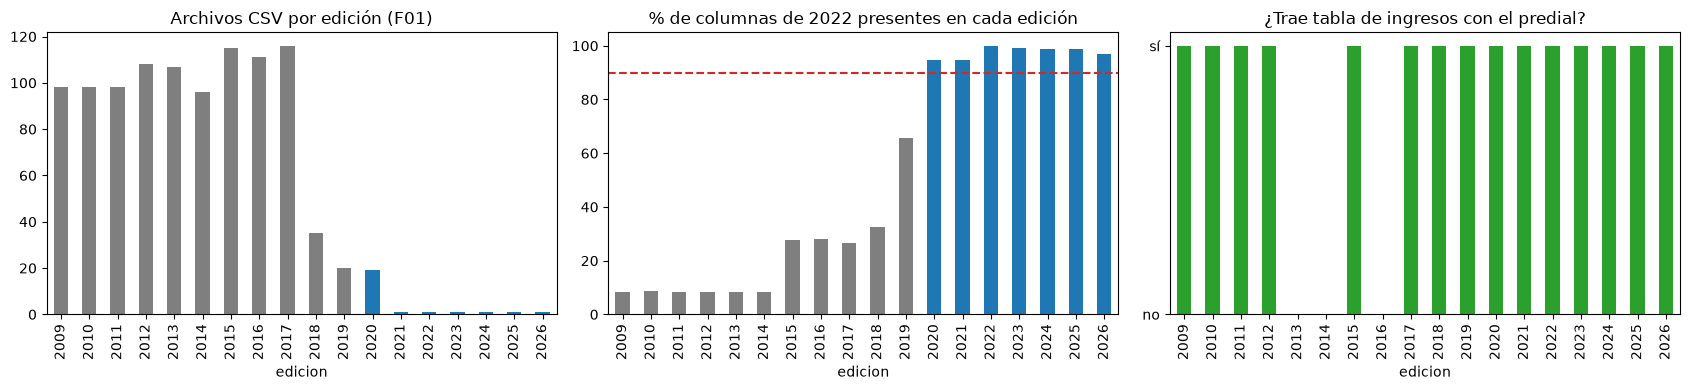

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
colores = ["tab:gray" if a < 2020 else "tab:blue" for a in df_inv.index]
df_inv["csv"].plot.bar(ax=ax[0], title="Archivos CSV por edición (F01)", color=colores)
df_inv["pct_columnas_comunes_2022"].plot.bar(ax=ax[1], title="% de columnas de 2022 presentes en cada edición", color=colores)
ax[1].axhline(90, ls="--", c="tab:red"); ax[1].set_ylim(0, 105)
df_inv["tabla_ingresos_predial"].astype(int).plot.bar(ax=ax[2], title="¿Trae tabla de ingresos con el predial?",
                                                       color=["tab:green" if v else "tab:red" for v in df_inv["tabla_ingresos_predial"]])
ax[2].set_yticks([0, 1], ["no", "sí"])
plt.tight_layout(); plt.show()

### 4.2 Ediciones 2020–2026 (rango de análisis): llave, tipo de municipalidad y tabla de ingresos

In [20]:
A0, A1 = cfg["anios"]["renamu_analisis"]
def _col(cols, nombre):
    return next((c for c in cols if c.lower() == nombre.lower()), None)
ren, ubigeos_renamu = [], {}
for r in f01[(f01["anio"] >= A0) & (f01["anio"] <= A1)].itertuples():
    pdf = a_pandas(leer_csv(spark, r.abs, detectar_formato(RAIZ / r.ruta)))     # ~1 900 filas: se revisa en pandas
    cols = list(pdf.columns)
    cu, ct = _col(cols, "Ubigeo"), _col(cols, "Tipomuni")
    ubi = pdf[cu] if cu else pdf[_col(cols, "ccdd")].str.zfill(2) + pdf[_col(cols, "ccpp")].str.zfill(2) + pdf[_col(cols, "ccdi")].str.zfill(2)
    valido = ubi.str.fullmatch(r"\d{6}").fillna(False)
    ubigeos_renamu.setdefault(r.anio, set()).update(ubi[valido])
    ren.append({"edicion": r.anio, "archivo": r.archivo, "filas": len(pdf), "columnas": len(cols), "ubigeo_origen": cu or "ccdd+ccpp+ccdi",
                "filas_sin_ubigeo_valido": int((~valido).sum()), "ubigeo_unicos": ubi[valido].nunique(),
                "ubigeo_duplicados": int(valido.sum() - ubi[valido].nunique()),
                "tipomuni": ", ".join(f"{k}={v}" for k, v in sorted(Counter(pdf[ct][valido]).items())) if ct else None,
                "cols_C96": sum(c.upper().startswith("C96") for c in cols)})
df_ren = pd.DataFrame(ren)
resumen_ren = df_ren.groupby("edicion").agg(archivos=("archivo", "count"), municipalidades=("ubigeo_unicos", "max"), columnas=("columnas", "sum"),
                                            filas_sin_ubigeo=("filas_sin_ubigeo_valido", "sum"), ubigeo_duplicados=("ubigeo_duplicados", "sum"),
                                            tipomuni=("tipomuni", "first"), cols_C96=("cols_C96", "sum"))
display(resumen_ren)
display(df_ren[df_ren["filas_sin_ubigeo_valido"] > 0][["edicion", "archivo", "filas", "filas_sin_ubigeo_valido"]])
check("BRZ-F3-001", "UBIGEO válido único por municipalidad (RENAMU 2020–2026)", int(df_ren["filas"].sum()), int(df_ren["ubigeo_duplicados"].sum()), "critica")
check("BRZ-F3-002", "Todas las ediciones 2020–2026 traen la tabla de ingresos C96", len(resumen_ren), int((resumen_ren["cols_C96"] == 0).sum()))
check("BRZ-F3-003", "Filas del RENAMU sin UBIGEO válido", int(df_ren["filas"].sum()), int(df_ren["filas_sin_ubigeo_valido"].sum()))

,archivos,municipalidades,columnas,filas_sin_ubigeo,ubigeo_duplicados,tipomuni,cols_C96
edicion,,,,,,,
2020,19,1874,1534,8,0,"1=196, 2=1678",57
2021,1,1874,1300,0,0,"1=196, 2=1678",57
2022,1,1874,1368,0,0,"1=196, 2=1678",57
2023,1,1891,1383,0,0,"1=196, 2=1695",57
2024,1,1891,1388,0,0,"1=196, 2=1695",57
2025,1,1891,1388,0,0,"1=196, 2=1695",57
2026,1,1892,1397,0,0,"1=196, 2=1696",64


,edicion,archivo,filas,filas_sin_ubigeo_valido
1,2020,C01.csv,1877,3
8,2020,C08.csv,1879,5


'ALERTA'

## 5. Conexión de prueba entre las tres fuentes

In [21]:
muni_siaf = df_ejec[df_ejec["tipo_ejecutora"].str.startswith("Municipalidad")]
anios_siaf = sorted(muni_siaf["anio"].unique())
cruce = []
for ed in range(A0, A1 + 1):
    anio = min(ed, max(anios_siaf))
    s, r = set(muni_siaf[muni_siaf["anio"] == anio]["ubigeo"]), ubigeos_renamu.get(ed, set())
    cruce.append({"edicion_RENAMU": ed, "anio_SIAF": anio, "municipalidades_SIAF": len(s), "municipalidades_RENAMU": len(r), "en_ambas": len(s & r),
                  "solo_SIAF": len(s - r), "solo_RENAMU": len(r - s), "pct_SIAF_con_RENAMU": round(100 * len(s & r) / len(s), 2)})
df_cruce = pd.DataFrame(cruce)
print("SIAF ↔ RENAMU por UBIGEO")
display(df_cruce)

sec_siaf = set(muni_siaf["SEC_EJEC"])
sec_f2 = set(a_pandas(ee.where("anio >= 2019").select("SEC_EJEC").distinct())["SEC_EJEC"])
pares_siaf = set(zip(muni_siaf[muni_siaf["anio"] == 2024]["SEC_EJEC"], muni_siaf[muni_siaf["anio"] == 2024]["ubigeo"]))
pares_f2 = set(map(tuple, a_pandas(esat).values))
comunes = {s for s, _ in pares_f2} & {s for s, _ in pares_siaf}
coinc = len({p for p in pares_f2 if p[0] in comunes} & pares_siaf)
print("SIAF ↔ SISMEPRE por SEC_EJEC")
display(pd.DataFrame([{"SEC_EJEC_SISMEPRE_2019_2026": len(sec_f2), "existen_en_SIAF": len(sec_f2 & sec_siaf),
                       "puente_SEC_EJEC_UBIGEO_comparados_2024": len(comunes), "puente_coincide_con_SIAF": coinc}]))
check("BRZ-X-001", "Municipalidades del SIAF con UBIGEO en el RENAMU de la misma edición", int(df_cruce["municipalidades_SIAF"].sum()), int(df_cruce["solo_SIAF"].sum()))
check("BRZ-X-002", "SEC_EJEC del SISMEPRE existen en el SIAF", len(sec_f2), len(sec_f2 - sec_siaf), "critica")
check("BRZ-X-003", "El puente SEC_EJEC→UBIGEO del SISMEPRE coincide con el del SIAF", len(comunes), len(comunes) - coinc, "critica")

SIAF ↔ RENAMU por UBIGEO


,edicion_RENAMU,anio_SIAF,municipalidades_SIAF,municipalidades_RENAMU,en_ambas,solo_SIAF,solo_RENAMU,pct_SIAF_con_RENAMU
0,2020,2020,1874,1874,1874,0,0,100.00
1,2021,2021,1890,1874,1874,16,0,99.15
2,2022,2022,1890,1874,1874,16,0,99.15
3,2023,2023,1891,1891,1891,0,0,100.00
4,2024,2024,1891,1891,1891,0,0,100.00
5,2025,2025,1892,1891,1891,1,0,99.95
6,2026,2026,1892,1892,1892,0,0,100.00


SIAF ↔ SISMEPRE por SEC_EJEC


,SEC_EJEC_SISMEPRE_2019_2026,existen_en_SIAF,puente_SEC_EJEC_UBIGEO_comparados_2024,puente_coincide_con_SIAF
0,1449,1449,1128,1128


'OK'

## 6. Bitácora de la ejecución

Las verificaciones de este notebook se guardan en `data/bronze/bitacora_ejecuciones.jsonl`. La auditoría las consolidará más adelante.

In [22]:
df_checks = pd.DataFrame(CHECKS)
display(df_checks)
bitacora = {"run_id": RUN_ID, "notebook": "02_bronze_perfilado", "fin_utc": bronze._ahora(),
            "filas_leidas": {"F1": int(df_anual["filas_spark"].sum()), "F2": int(df_est_f2["filas_spark"].sum()), "F3_analisis": int(df_ren["filas"].sum())},
            "verificaciones": CHECKS}
with open(ruta("bronze") / "bitacora_ejecuciones.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(bitacora, ensure_ascii=False) + "\n")
print(df_checks["estado"].value_counts().to_string())
criticas = df_checks[(df_checks["severidad"] == "critica") & (df_checks["estado"] != "OK")]
assert criticas.empty, criticas

,regla,descripcion,severidad,filas_evaluadas,filas_fallidas,estado
0,BRZ-F1-001,Los 18 archivos del SIAF tienen las mismas 36 ...,critica,18,0,OK
1,BRZ-F1-002,Conteo de Spark = conteo físico del manifest (...,critica,18,0,OK
2,BRZ-F1-003,"NIVEL_GOBIERNO solo toma E, R o M",alta,15202372,0,OK
3,BRZ-F1-004,ANO_DOC coincide con el año del archivo,critica,15202372,0,OK
4,BRZ-F1-005,"Montos numéricos parseables (PIA, PIM, recaudado)",critica,45607116,0,OK
5,BRZ-F1-006,Un UBIGEO corresponde a una sola municipalidad...,critica,33598,0,OK
6,BRZ-F1-007,Sin filas duplicadas exactas,critica,15202372,0,OK
7,BRZ-F1-008,"Llave de negocio única (año, mes, ejecutora, f...",alta,15202372,291,ALERTA
8,BRZ-F2-002,Cada archivo del SISMEPRE tiene una llave natu...,alta,7,0,OK
9,BRZ-F2-001,Filas del SISMEPRE con estructura CSV válida,alta,493789,9,ALERTA


estado
OK        13
ALERTA     4


In [23]:
spark.stop()